# 02 — EDA on the 2023–2025 AQI Dataset
**Input:** `data/Cleaned/aqi_2023_2025_clean.csv` (output of your cleaning notebook)
**Output:** plots saved in `reports/figures/` with the prefix `2023_25_`

**What this file can show:** city/state AQI, trends over time, seasonality, AQI category balance, which pollutant dominates.
**What it cannot show:** pollutant concentrations (no PM2.5/NO2 columns), so no pollutant correlation heatmap and no PM2.5-vs-AQI scatter here. Those live in the `city_day.csv` EDA.

In [14]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_style("whitegrid")
FIG = "../reports/figures/2023_25"
os.makedirs(FIG, exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(f"{FIG}/2023_25_{name}.png", dpi=150)
    plt.show()


## Step 0 — Load the cleaned file
The cell below also handles two things that commonly differ between teammates' cleaned files: column names (it renames the raw Kaggle names if they're still present) and the date format (it tries `YYYY-MM-DD` first, then `DD-MM-YYYY`).

In [15]:
df = pd.read_csv("../data/Cleaned/aqi_2023_2025_clean.csv")

df = df.rename(columns={'area':'City','aqi_value':'AQI','air_quality_status':'AQI_Bucket','date':'Date'})

d = pd.to_datetime(df['Date'], format='%Y-%m-%d', errors='coerce')
if d.isna().mean() > 0.5:
    d = pd.to_datetime(df['Date'], format='%d-%m-%Y', errors='coerce')
df['Date'] = d

df['year']  = df['Date'].dt.year
df['month'] = df['Date'].dt.month

print("Shape:", df.shape)
print("Date range:", df['Date'].min(), "to", df['Date'].max())
print("Unparseable dates:", df['Date'].isna().sum())
df.head()


Shape: (235005, 9)
Date range: 2022-04-01 00:00:00 to 2025-04-30 00:00:00
Unparseable dates: 0


,Date,state,City,number_of_monitoring_stations,prominent_pollutants,AQI,AQI_Bucket,year,month
0,2022-04-01,Tripura,Agartala,2,"PM10,SO2",78,Satisfactory,2022,4
1,2022-04-02,Tripura,Agartala,2,"PM10,SO2",77,Satisfactory,2022,4
2,2022-04-03,Tripura,Agartala,2,"PM2.5,PM10",76,Satisfactory,2022,4
3,2022-04-04,Tripura,Agartala,2,PM10,57,Satisfactory,2022,4
4,2022-04-05,Tripura,Agartala,2,PM10,64,Satisfactory,2022,4


In [16]:
# Quick summary statistics
print(df['AQI'].describe())
print()
print("Cities:", df['City'].nunique(), "| States:", df['state'].nunique() if 'state' in df else 'n/a')
print("Columns:", list(df.columns))


count    235005.000000
mean        111.082526
std          71.463803
min           3.000000
25%          59.000000
50%          92.000000
75%         142.000000
max         500.000000
Name: AQI, dtype: float64

Cities: 291 | States: 32
Columns: ['Date', 'state', 'City', 'number_of_monitoring_stations', 'prominent_pollutants', 'AQI', 'AQI_Bucket', 'year', 'month']


**What to expect:** about 291 cities, 32 states, dates from Jan 2023 to Apr 2025. AQI should range roughly 0–500. If `Unparseable dates` is not 0, fix the date step before continuing.

## Plot 1 — City-wise average AQI
**Why it matters:** shows which cities are most polluted on average and confirms whether `City` should be a strong feature in the model. With 291 cities we show the worst 15 and best 10.

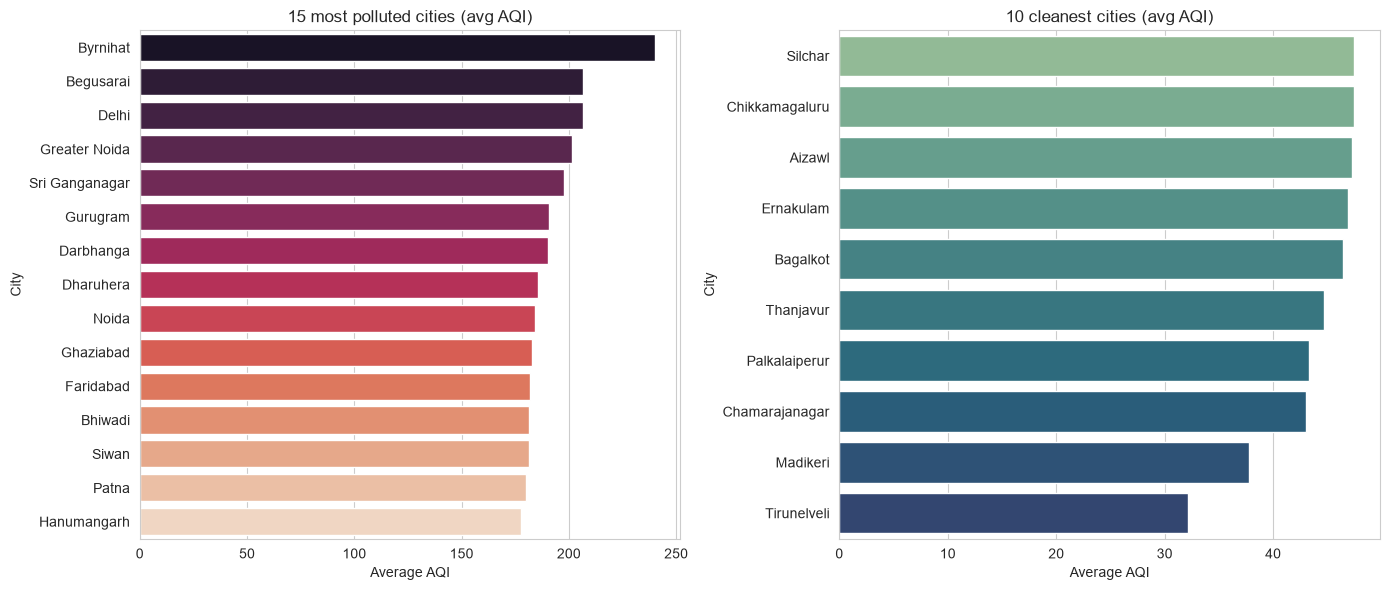

In [17]:
city_avg = df.groupby('City')['AQI'].mean().sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
top = city_avg.head(15)
sns.barplot(x=top.values, y=top.index, hue=top.index, legend=False, palette="rocket", ax=ax[0])
ax[0].set_title("15 most polluted cities (avg AQI)"); ax[0].set_xlabel("Average AQI")

bot = city_avg.tail(10)
sns.barplot(x=bot.values, y=bot.index, hue=bot.index, legend=False, palette="crest", ax=ax[1])
ax[1].set_title("10 cleanest cities (avg AQI)"); ax[1].set_xlabel("Average AQI")
save("city_avg_aqi")


## Plot 2 — State-wise average AQI
**Why it matters:** the 2015–2020 file has no state column, so this regional view is unique to this dataset. It smooths out single-city noise.

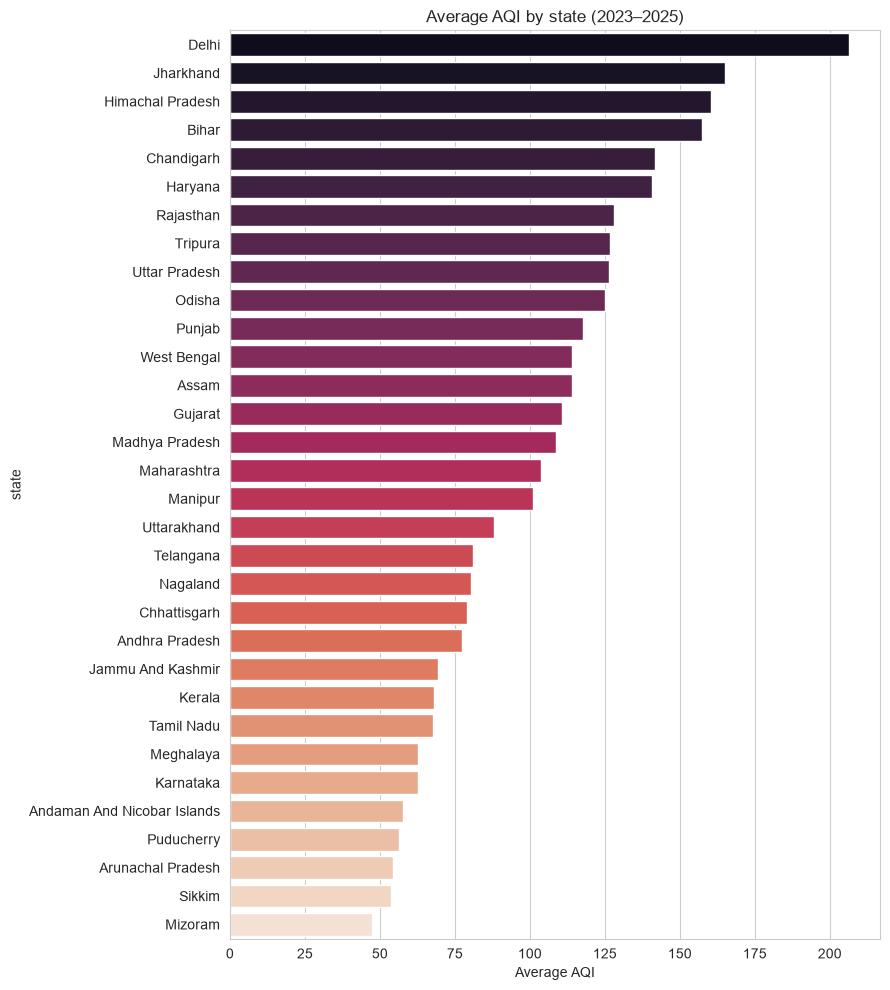

In [18]:
if 'state' in df.columns:
    state_avg = df.groupby('state')['AQI'].mean().sort_values(ascending=False)
    plt.figure(figsize=(9, 10))
    sns.barplot(x=state_avg.values, y=state_avg.index, hue=state_avg.index, legend=False, palette="rocket")
    plt.xlabel("Average AQI"); plt.title("Average AQI by state (2023–2025)")
    save("state_avg_aqi")


## Plot 3 — AQI over time
**Why it matters:** reveals seasonal and yearly trends (winter spikes), which justifies adding `month`, `season` and a winter flag as features.
First the national picture (average over all cities per day), then selected cities.

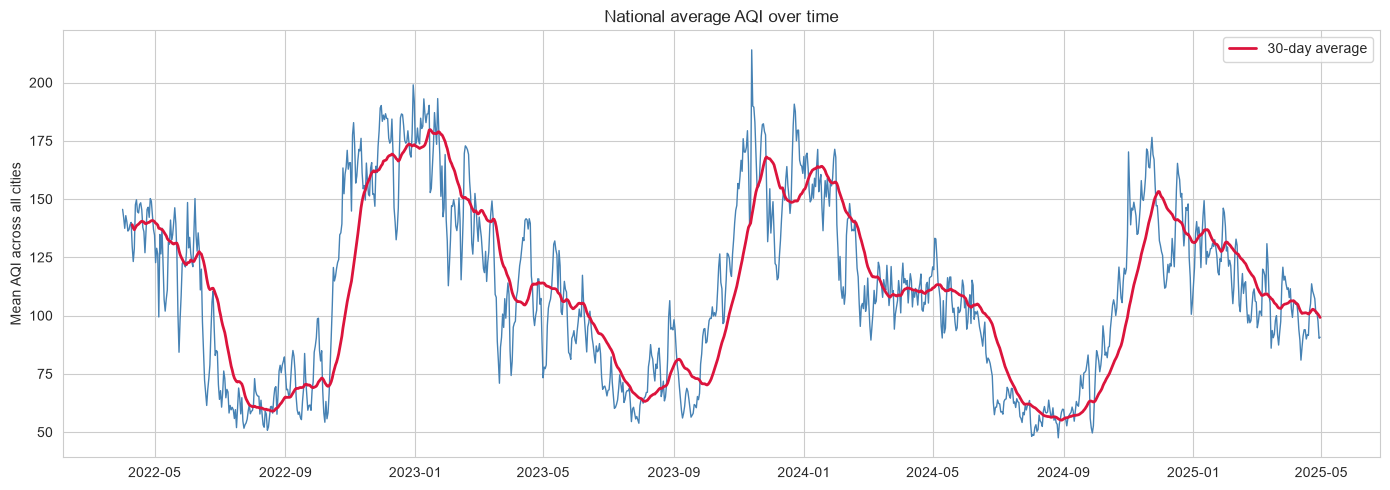

In [19]:
daily = df.groupby('Date')['AQI'].mean()
plt.figure(figsize=(14, 5))
plt.plot(daily.index, daily.values, color='steelblue', lw=1)
plt.plot(daily.rolling(30, min_periods=10).mean(), color='crimson', lw=2, label='30-day average')
plt.ylabel("Mean AQI across all cities"); plt.title("National average AQI over time")
plt.legend()
save("national_trend")


In [ ]:
# Selected cities (falls back to the 3 most polluted if a name isn't in this file)
wanted = ['Delhi', 'Chandigarh', 'Mumbai', 'Ludhiana']
cities = [c for c in wanted if c in df['City'].unique()]
if len(cities) < 2:
    cities = list(city_avg.head(3).index)
print("Plotting:", cities)

plt.figure(figsize=(14, 6))
for c in cities:
    s = df[df['City'] == c].sort_values('Date')
    plt.plot(s['Date'], s['AQI'], label=c, alpha=0.75)
plt.ylabel("AQI"); plt.title("AQI over time — selected cities"); plt.legend()
save("selected_cities_trend")


## Plot 4 — Monthly boxplot of AQI
**Why it matters:** shows spread and outliers per month and which months are worst (usually Oct–Jan in North India: stubble burning, Diwali, winter inversion).

In [ ]:
plt.figure(figsize=(12, 6))
sns.boxplot(x='month', y='AQI', data=df, hue='month', legend=False, palette="coolwarm")
plt.title("AQI distribution by month (all cities, 2023–2025)")
save("monthly_boxplot")

print(df.groupby('month')['AQI'].median().round(1))


**What to expect:** highest medians in Nov–Jan, lowest in Jul–Sep (monsoon). Note this down; it is the evidence for your `is_winter` feature.

## Plot 5 — Year-over-year comparison (fair version)
2025 only runs to about April, so comparing a full 2023 with a partial 2025 is unfair. We compare **Jan–Apr only** for all three years.

In [ ]:
jan_apr = df[df['month'].between(1, 4)]
fair = jan_apr.groupby('year')['AQI'].mean()
print(fair.round(1))

plt.figure(figsize=(7, 5))
fair.plot(kind='bar', color=['#4c72b0', '#55a868', '#c44e52'])
plt.ylabel("Mean AQI (Jan–Apr)"); plt.title("Jan–Apr mean AQI by year"); plt.xticks(rotation=0)
save("yearly_fair_comparison")


## Plot 6 — AQI_Bucket distribution
**Why it matters:** reveals class imbalance, which decides which classification metrics you can trust (accuracy alone will mislead if a class is rare).

In [ ]:
order = ['Good', 'Satisfactory', 'Moderate', 'Poor', 'Very Poor', 'Severe']
order = [o for o in order if o in df['AQI_Bucket'].unique()]

plt.figure(figsize=(8, 5))
sns.countplot(x='AQI_Bucket', data=df, order=order, hue='AQI_Bucket', legend=False, palette="rocket")
plt.xticks(rotation=25); plt.title("AQI category distribution (2023–2025)")
save("bucket_distribution")

print(df['AQI_Bucket'].value_counts())
print((df['AQI_Bucket'].value_counts(normalize=True) * 100).round(1))


## Plot 7 — Dominant pollutant (replaces the pollutant heatmap)
We have no concentrations, but `prominent_pollutants` says *which* pollutant drove the AQI that day. Some rows list several, so we split them first.

In [ ]:
if 'prominent_pollutants' in df.columns:
    poll = df.assign(pollutant=df['prominent_pollutants'].astype(str).str.split(',')).explode('pollutant')
    poll['pollutant'] = poll['pollutant'].str.strip()
    counts = poll['pollutant'].value_counts().head(8)

    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    sns.barplot(x=counts.values, y=counts.index, hue=counts.index, legend=False, palette="viridis", ax=ax[0])
    ax[0].set_title("How often each pollutant is dominant"); ax[0].set_xlabel("City-days")

    top_p = counts.index[:6]
    sns.boxplot(x='pollutant', y='AQI', data=poll[poll['pollutant'].isin(top_p)], order=top_p,
                hue='pollutant', legend=False, palette="viridis", ax=ax[1])
    ax[1].set_title("AQI when each pollutant is dominant")
    save("dominant_pollutant")


**What to expect:** PM2.5 and PM10 dominate most days, and AQI is highest on days when they are the dominant pollutant. That matches the PM2.5 finding from the 2015–2020 data.

## Plot 8 — Monitoring stations vs AQI (replaces the PM2.5 scatter)
Checks whether the number of stations relates to AQI, and whether low-station cities have less reliable averages.

In [ ]:
if 'number_of_monitoring_stations' in df.columns:
    plt.figure(figsize=(8, 6))
    sns.scatterplot(x='number_of_monitoring_stations', y='AQI', data=df.sample(min(20000, len(df)), random_state=1), alpha=0.25)
    plt.title("Monitoring stations vs AQI (sample of rows)")
    save("stations_vs_aqi")

    num = df[['AQI', 'number_of_monitoring_stations', 'month', 'year']].corr()
    plt.figure(figsize=(6, 5))
    sns.heatmap(num, annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Correlation of numeric columns")
    save("numeric_corr")


## Plot 9 — Delhi vs Chandigarh vs Mumbai (project extension)

In [ ]:
trio = [c for c in ['Delhi', 'Chandigarh', 'Mumbai'] if c in df['City'].unique()]
print("Found in this file:", trio, "| missing:", [c for c in ['Delhi','Chandigarh','Mumbai'] if c not in trio])

sub = df[df['City'].isin(trio)]
pct = (sub.groupby(['City', 'AQI_Bucket']).size().unstack(fill_value=0)
          .reindex(columns=order, fill_value=0))
pct = pct.div(pct.sum(axis=1), axis=0) * 100

pct.plot(kind='bar', stacked=True, figsize=(8, 6), colormap='RdYlGn_r')
plt.ylabel("% of days"); plt.xticks(rotation=0)
plt.title("AQI category mix"); plt.legend(title="Category", bbox_to_anchor=(1.02, 1), loc='upper left')
save("trio_category_mix")
print(sub.groupby('City')['AQI'].agg(['mean', 'median', 'max']).round(1))


## Findings to write in your report
Fill these in from your own outputs:
- Most polluted cities / states:
- Cleanest cities / states:
- Worst months and best months:
- Year-over-year direction (Jan–Apr comparison):
- Class balance of AQI_Bucket (which categories are rare):
- Dominant pollutant nationally:
- How Delhi, Chandigarh and Mumbai compare:

**How this feeds the next step:** the month pattern justifies `month`, `season` and `is_winter` features; the category imbalance means you should report precision, recall and F1 per class, not just accuracy; and since this file has no pollutant concentrations it supports **classification of AQI_Bucket**, not pollutant regression.